<a href="https://www.kaggle.com/code/gonaldomichael/cnn-classifica-o-de-imagens-redes-neuronais?scriptVersionId=371179396" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Classificação de Imagens com CNN — CIFAR-10

Pipeline end-to-end de **visão computacional** com redes neuronais convolucionais (CNN), usando o dataset público **CIFAR-10** (disponível diretamente no Keras): 60.000 imagens coloridas de 32×32 píxeis, divididas por 10 categorias — aviões, automóveis, pássaros, gatos, veados, cães, rãs, cavalos, navios e camiões (50.000 de treino / 10.000 de teste).

**Origem do projeto:** projeto de estudo de deep learning para classificação multiclasse de imagens, construído de raiz no Databricks, célula a célula, com validação do utilizador em cada etapa.

**Objetivo:** treinar uma CNN (camadas convolucionais, pooling e dropout) capaz de classificar imagens CIFAR-10 nas 10 categorias com acurácia acima do limiar definido, e analisar o comportamento do modelo com perguntas de negócio (quais categorias confunde, animais vs veículos, impacto de fundos e cores, falsos positivos, overfitting).

**Métrica de sucesso:** acurácia ≥ 70% no conjunto de teste (limiar honesto para uma CNN simples; abaixo disso o modelo não é aceitável).

**Metodologia:** divisão treino/teste desde o início (evita leakage), normalização dos píxeis para [0, 1], one-hot encoding das etiquetas, CNN com Adam e categorical crossentropy, avaliação com acurácia e matriz de confusão, seguida de 7 células de perguntas de negócio.

**RESULTADO FINAL (encerrado 2026-11-18, todos os números verificados por execução):** modelo final — CNN com 2 blocos convolucionais (32 e 64 filtros, MaxPooling, dropout 0.25/0.5, Dense 256; ~1,12M parâmetros), otimizador Adam e categorical crossentropy, treinada em 20 épocas. **Acurácia no teste: 77,75%** (meta ≥ 70% CUMPRIDA). Melhor classe: automóvel (90,4%); pior: gato (58,3%). Confusão dominante: gato↔cão (301 confusões bidirecionais, 13,5% dos 2.225 erros). Veículos 85,9% vs animais 72,3% (erro concentrado em animais: 74,6% dos erros). Mais falsos positivos: cão (389; em taxa, gato 39,3%). Complexidade visual não prediz o erro (P4: NÃO). Efeito de 40 épocas (P7): **ganho marginal (+0,62% no teste) com overfitting instalado** (hiato treino-validação 3,6→7,8 p.p.) — manter 20 épocas. 7 perguntas de negócio respondidas com dados (P1–P7). Artefactos de publicação (5 CSVs + README gerado com os números reais) exportados para `publicacao_kaggle_cnn_cifar10/` — prontos para Git e Kaggle.

In [1]:
# ==============================================================================
# STEP 0: AMBIENTE — TENSORFLOW/KERAS
# ==============================================================================
# Objectivo: garantir o TensorFlow no ambiente. No Kaggle o TensorFlow já vem
# pré-instalado; se não existir, instalamos por pip. (Na versão original,
# Databricks, esta célula instalava o pacote por magic e reiniciava o
# interpretador.)
import subprocess, sys

try:
    import tensorflow as tf
    print(f'TensorFlow {tf.__version__} já disponível no ambiente.')
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'tensorflow'], check=True)
    import tensorflow as tf
    print(f'TensorFlow {tf.__version__} instalado via pip.')

I0000 00:00:1795037737.848498      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795037753.365204      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0 já disponível no ambiente.


In [2]:
# ==============================================================================
# STEP 1: SETUP E MÉTRICA DE SUCESSO
# ==============================================================================
# Objectivo: Preparar o ambiente e definir o critério de sucesso do projeto.
#
# Input:  Nenhum (apenas importações)
# Output:  Seeds fixadas, limiares de sucesso e versões das bibliotecas
#
# Operações:
#   - Importar bibliotecas (TensorFlow/Keras, NumPy, Matplotlib)
#   - Fixar a seed de aleatoriedade para reprodutibilidade
#   - Definir a métrica de sucesso: acurácia mínima aceitável no teste

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

# Seed fixa para reprodutibilidade (mesmos resultados em cada execução)
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Métrica de sucesso: acurácia mínima de 70% no conjunto de teste.
# Uma CNN simples em CIFAR-10 deve ultrapassar 70%; abaixo disso, o modelo
# não é considerado aceitável para produção.
MIN_ACCURACY = 0.70

print("Versões das bibliotecas:")
print(f"  TensorFlow: {tf.__version__}")
print(f"  NumPy:      {np.__version__}")
print(f"  Keras:      {keras.__version__}")
print(f"\nMétrica de sucesso: acurácia >= {MIN_ACCURACY:.0%} no conjunto de teste")

Versões das bibliotecas:
  TensorFlow: 2.21.0
  NumPy:      2.1.3
  Keras:      3.13.2

Métrica de sucesso: acurácia >= 70% no conjunto de teste


In [3]:
# ==============================================================================
# STEP 2: CARREGAMENTO DO CIFAR-10 E DIVISÃO TREINO/TESTE DESDE O INÍCIO
# ==============================================================================
# Objectivo: Carregar o dataset CIFAR-10 directamente do Keras, já dividido em
# treino e teste (evita leakage de dados), explorar a estrutura (dimensões,
# tipos, intervalo de valores) e validar a segurança dos dados.
#
# Input:  Dataset CIFAR-10 — /kaggle/input (anexado) ou Keras (fallback)
# Output: x_train, y_train, x_test, y_test, CLASS_NAMES (variáveis globais)
#
# Operações:
#   - Carregar o CIFAR-10 com a divisão original 50.000 treino / 10.000 teste
#   - Explorar dimensões, tipos e conteúdo dos arrays
#   - Validar segurança: valores nulos, intervalo de píxeis, etiquetas válidas
#   - Confirmar distribuição equilibrada das 10 classes

import numpy as np
import pandas as pd
from tensorflow.keras.datasets import cifar10

# Nomes das 10 categorias pela ordem oficial do CIFAR-10 (índices 0 a 9)
CLASS_NAMES = ['avião', 'automóvel', 'pássaro', 'gato', 'veado',
               'cão', 'rã', 'cavalo', 'navio', 'camião']

# --- Carregamento: o split treino/teste é o oficial do dataset -------------
# Desde o primeiro momento, evitando qualquer fuga de dados (leakage)
import os
import glob as _glob
# --- Carregamento: Kaggle Input (dataset .npy anexado) ou Keras como fallback --
# O dataset do projeto está em dataset/ do repositório (5 ficheiros .npy).
# No Kaggle: anexar como Dataset — é detetado automaticamente em /kaggle/input.
# Sem o dataset anexado: descarrega do Keras (mesma divisão oficial, sem leakage).
_npy = _glob.glob('/kaggle/input/**/x_train_parte1.npy', recursive=True)
if _npy:
    _pasta = os.path.dirname(_npy[0])
    x_train = np.concatenate([np.load(os.path.join(_pasta, 'x_train_parte1.npy')),
                              np.load(os.path.join(_pasta, 'x_train_parte2.npy'))])
    y_train = np.load(os.path.join(_pasta, 'y_train.npy'))
    x_test = np.load(os.path.join(_pasta, 'x_test.npy'))
    y_test = np.load(os.path.join(_pasta, 'y_test.npy'))
    print(f'Dataset carregado do Kaggle Input: {_pasta}')
else:
    (x_train, y_train), (x_test, y_test) = cifar10.load_data()
    print('Dataset carregado do Keras (dataset .npy não anexado).')

# --- Exploração da estrutura e dimensões -------------------------------------
print("Dimensões dos arrays:")
print(f"  x_train: {x_train.shape} | y_train: {y_train.shape}")
print(f"  x_test : {x_test.shape} | y_test : {y_test.shape}")
print(f"\nTipos: píxeis = {x_train.dtype}, etiquetas = {y_train.dtype}")
print(f"Estrutura de cada imagem: {x_train.shape[1]}x{x_train.shape[2]} píxeis, {x_train.shape[3]} canais (RGB)")

# --- Validação de segurança dos dados (antes de qualquer transformação) -----
print("\n--- Segurança dos dados ---")
print(f"Intervalo de valores dos píxeis (treino): [{x_train.min()}, {x_train.max()}]")
print(f"Imagens com valores nulos (treino): {np.isnan(x_train).sum()}")
print(f"Imagens com valores nulos (teste) : {np.isnan(x_test).sum()}")
print(f"Etiquetas únicas no treino: {sorted(np.unique(y_train).tolist())}")
print(f"Etiquetas únicas no teste : {sorted(np.unique(y_test).tolist())}")

# Confirmar que as etiquetas estão dentro do intervalo válido [0, 9]
assert set(np.unique(y_train)).issubset(set(range(10))), "Etiquetas inválidas no treino!"
assert set(np.unique(y_test)).issubset(set(range(10))), "Etiquetas inválidas no teste!"
print("OK: todas as etiquetas são válidas (0 a 9) e não há valores nulos.")

# --- Distribuição das classes (verificar equilíbrio) -------------------------
dist_treino = pd.Series(y_train.flatten()).value_counts().sort_index()
dist_teste = pd.Series(y_test.flatten()).value_counts().sort_index()
distribuicao = pd.DataFrame({
    'classe': CLASS_NAMES,
    'imagens_treino': dist_treino.values,
    'imagens_teste': dist_teste.values,
})
print("\nDistribuição das classes:")
print(distribuicao.to_string(index=False))
print(f"\nTotal: {len(x_train)} imagens de treino + {len(x_test)} imagens de teste = {len(x_train) + len(x_test)}")
print("\nSTEP 2 concluído: dataset carregado, estrutura validada e split seguro.")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1144s 7us/step
Dataset carregado do Keras (dataset .npy não anexado).
Dimensões dos arrays:
  x_train: (50000, 32, 32, 3) | y_train: (50000, 1)
  x_test : (10000, 32, 32, 3) | y_test : (10000, 1)

Tipos: píxeis = uint8, etiquetas = uint8
Estrutura de cada imagem: 32x32 píxeis, 3 canais (RGB)

--- Segurança dos dados ---
Intervalo de valores dos píxeis (treino): [0, 255]
Imagens com valores nulos (treino): 0
Imagens com valores nulos (teste) : 0
Etiquetas únicas no treino: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Etiquetas únicas no teste : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
OK: todas as etiquetas são válidas (0 a 9) e não há valores nulos.

Distribuição das classes:
   classe  imagens_treino  imagens_teste
    avião            5000           1000
automóvel            5000           1000
  pássaro            5000           1000
     gato            5000           1000
    veado            5000           1000
      cão            5000           1000
       rã  

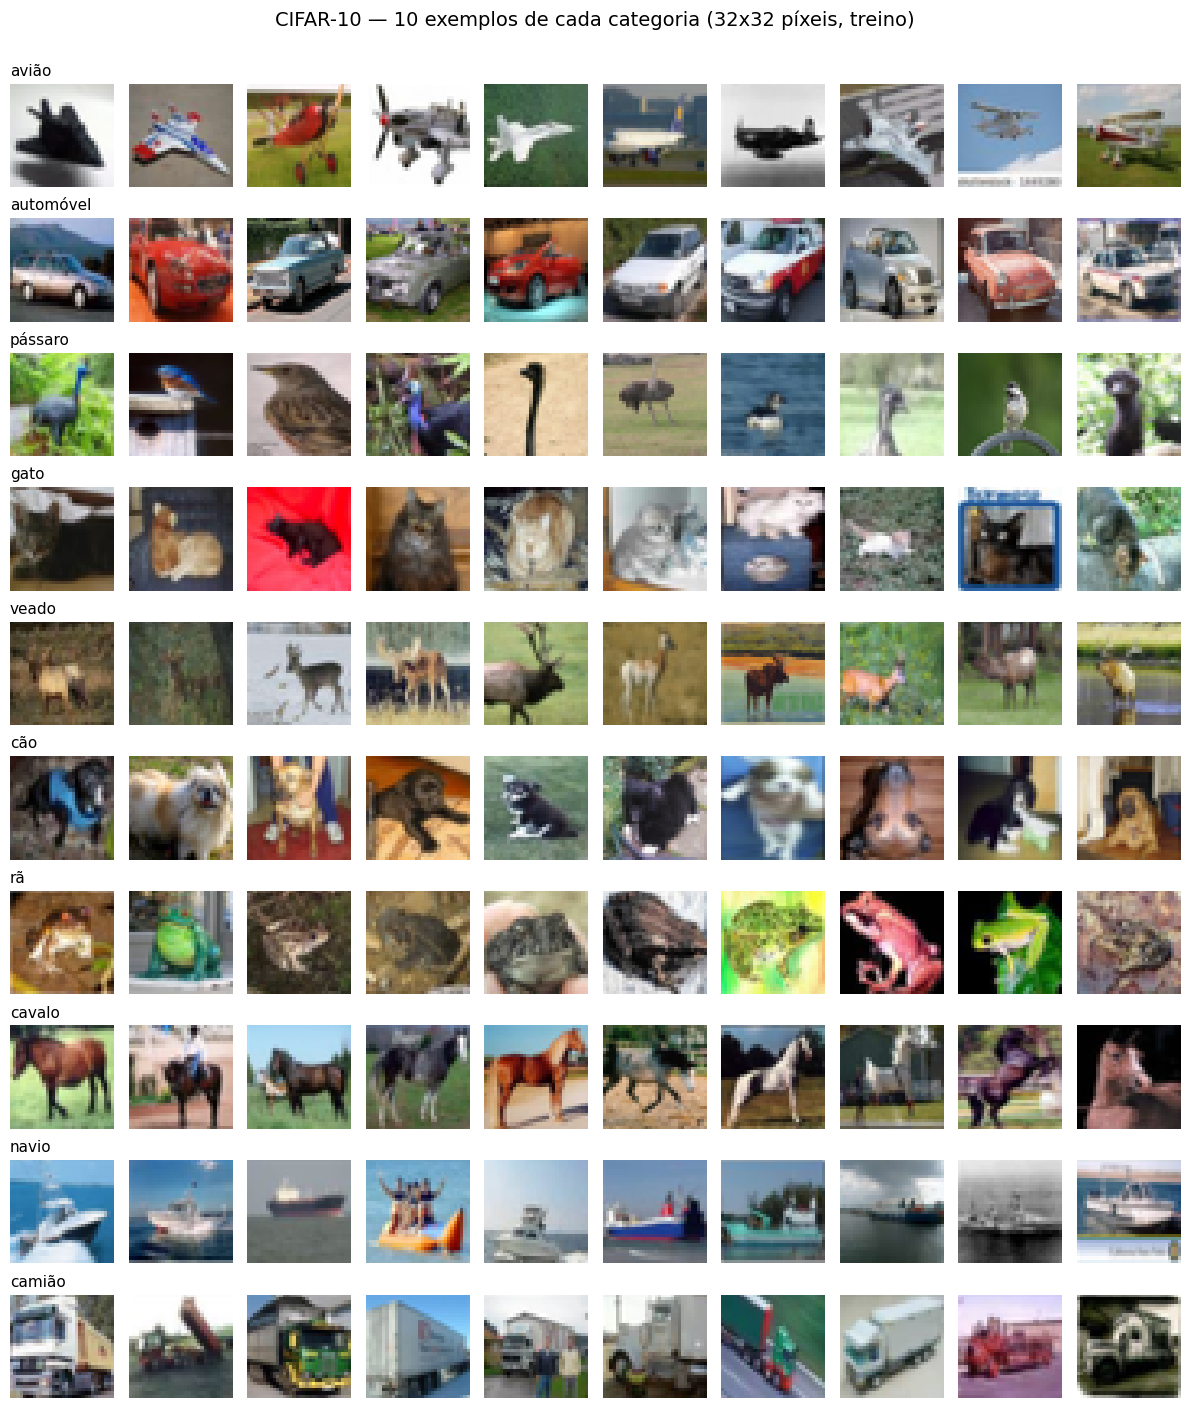

Validação da amostragem:
  avião      10 imagens
  automóvel  10 imagens
  pássaro    10 imagens
  gato       10 imagens
  veado      10 imagens
  cão        10 imagens
  rã         10 imagens
  cavalo     10 imagens
  navio      10 imagens
  camião     10 imagens

STEP 3 concluído: exemplos visuais de todas as categorias em grelha 10x10.


In [4]:
# ==============================================================================
# STEP 3: VISUALIZAÇÃO DE IMAGENS DE EXEMPLO DE CADA CATEGORIA
# ==============================================================================
# Objectivo: Ver imagens reais de cada uma das 10 categorias do CIFAR-10 para
# perceber o tipo de dados, a resolução (32x32), a variedade de fundos e a
# dificuldade de classificação antes de treinar o modelo.
#
# Input:  x_train, y_train, CLASS_NAMES (do STEP 2)
# Output: Grelha 10x10 de imagens (10 exemplos de cada categoria)
#
# Operações:
#   - Para cada categoria, selecionar as primeiras 10 imagens de treino
#   - Desenhar grelha 10 classes x 10 exemplos com Matplotlib
#   - Validar visualmente que as imagens correspondem às etiquetas

import numpy as np
import matplotlib.pyplot as plt

# --- Seleção: 10 primeiras imagens de cada categoria --------------------------
EXEMPLOS_POR_CLASSE = 10

fig, axes = plt.subplots(
    nrows=len(CLASS_NAMES), ncols=EXEMPLOS_POR_CLASSE,
    figsize=(12, 14),
)

for classe_idx, nome_classe in enumerate(CLASS_NAMES):
    # Índices das imagens desta classe (apenas do conjunto de TREINO)
    idxs = np.where(y_train.flatten() == classe_idx)[0][:EXEMPLOS_POR_CLASSE]

    for j, img_idx in enumerate(idxs):
        ax = axes[classe_idx, j]
        # imshow espera valores 0-255 (ainda não normalizados) com dtype int
        ax.imshow(x_train[img_idx])
        ax.axis('off')
        # Nome da classe na primeira coluna
        if j == 0:
            ax.set_title(nome_classe, fontsize=11, loc='left')

plt.suptitle('CIFAR-10 — 10 exemplos de cada categoria (32x32 píxeis, treino)',
             fontsize=14, y=1.005)
plt.tight_layout()
plt.show()

# --- Validação: confirmar que selecionámos 10 imagens de cada classe ----------
print('Validação da amostragem:')
for classe_idx, nome_classe in enumerate(CLASS_NAMES):
    n = (np.where(y_train.flatten() == classe_idx)[0][:EXEMPLOS_POR_CLASSE]).shape[0]
    print(f'  {nome_classe:<10} {n} imagens')
print('\nSTEP 3 concluído: exemplos visuais de todas as categorias em grelha 10x10.')

In [5]:
# ==============================================================================
# STEP 4: NORMALIZAÇÃO DOS PÍXEIS E ONE-HOT ENCODING DAS ETIQUETAS
# ==============================================================================
# Objectivo: Preparar os dados para a rede neuronal — píxeis em [0, 1] para
# estabilizar o treino, e etiquetas em one-hot para a loss categorical
# crossentropy. O conjunto de teste recebe EXATAMENTE a mesma transformação,
# para que a avaliação final seja comparável.
#
# Input:  x_train, y_train, x_test, y_test (do STEP 2, valores 0-255)
# Output: x_train_norm, y_train_onehot, x_test_norm, y_test_onehot
#
# Operações:
#   - Converter píxeis para float32 e dividir por 255 (normalização [0, 1])
#   - One-hot encoding das etiquetas com to_categorical (10 classes)
#   - Validar: intervalo, tipo, dimensões e conteúdo das novas variáveis

import numpy as np
from tensorflow.keras.utils import to_categorical

# --- Normalização: 0-255 -> [0, 1] (float32 para precisão no treino) ----------
# Convertemos para float32 ANTES de dividir, para evitar arredondamentos inteiros
x_train_norm = x_train.astype('float32') / 255.0
x_test_norm = x_test.astype('float32') / 255.0

# --- One-hot encoding das etiquetas (0-9 -> vetor de 10 posições) -------------
# Ex.: etiqueta 3 (gato) -> [0, 0, 0, 1, 0, 0, 0, 0, 0, 0]
y_train_onehot = to_categorical(y_train, num_classes=10)
y_test_onehot = to_categorical(y_test, num_classes=10)

# --- Validação de segurança e de dimensões (regra 8) --------------------------
print('--- Validação pós-normalização ---')
print(f'Intervalo píxeis treino: [{x_train_norm.min():.4f}, {x_train_norm.max():.4f}]')
print(f'Intervalo píxeis teste : [{x_test_norm.min():.4f}, {x_test_norm.max():.4f}]')
print(f'Tipo dos dados: {x_train_norm.dtype}')

assert x_train_norm.min() >= 0.0 and x_train_norm.max() <= 1.0, 'Normalização treino fora de [0,1]!'
assert x_test_norm.min() >= 0.0 and x_test_norm.max() <= 1.0, 'Normalização teste fora de [0,1]!'

print(f'\nDimensões: x_train_norm {x_train_norm.shape} | x_test_norm {x_test_norm.shape}')
print(f'Dimensões: y_train_onehot {y_train_onehot.shape} | y_test_onehot {y_test_onehot.shape}')

# One-hot: cada linha deve somar exactamente 1 (uma única classe activa)
assert (y_train_onehot.sum(axis=1) == 1).all(), 'One-hot inválido no treino!'
assert (y_test_onehot.sum(axis=1) == 1).all(), 'One-hot inválido no teste!'

# Verificar coerência: etiqueta original vs posição do 1 no one-hot
exemplo = 0
print(f'\nExemplo de coerência (imagem {exemplo}):')
print(f'  Etiqueta original: {y_train[exemplo][0]} ({CLASS_NAMES[y_train[exemplo][0]]})')
print(f'  One-hot: {y_train_onehot[exemplo].astype(int)}')

print('\nSTEP 4 concluído: píxeis normalizados em [0,1] e etiquetas em one-hot validadas.')

--- Validação pós-normalização ---
Intervalo píxeis treino: [0.0000, 1.0000]
Intervalo píxeis teste : [0.0000, 1.0000]
Tipo dos dados: float32

Dimensões: x_train_norm (50000, 32, 32, 3) | x_test_norm (10000, 32, 32, 3)
Dimensões: y_train_onehot (50000, 10) | y_test_onehot (10000, 10)

Exemplo de coerência (imagem 0):
  Etiqueta original: 6 (rã)
  One-hot: [0 0 0 0 0 0 1 0 0 0]

STEP 4 concluído: píxeis normalizados em [0,1] e etiquetas em one-hot validadas.


In [6]:
# ==============================================================================
# STEP 5: AMOSTRA DAS PRIMEIRAS 77 LINHAS COM TODAS AS VARIÁVEIS VISÍVEIS
# ==============================================================================
# Objectivo: Mostrar a estrutura do dataset em formato tabular — as primeiras
# 77 imagens (linhas) de treino, já normalizadas, com todas as variáveis
# visíveis: identificador, etiqueta, classe, estatísticas de píxeis por canal
# e as 10 colunas do one-hot encoding.
#
# Input:  x_train_norm, y_train, y_train_onehot, CLASS_NAMES (STEPS 2 e 4)
# Output: df_preview — tabela 77 linhas x 20 colunas (display interactiva)
#
# Operações:
#   - Construir DataFrame: 1 linha = 1 imagem, com estatísticas por canal RGB
#   - Juntar as 10 colunas one-hot (a matriz que a CNN recebe como etiqueta)
#   - Validar: dimensões, nulos e coerência etiqueta vs one-hot

import numpy as np
import pandas as pd

N_LINHAS = 77  # primeiras 77 imagens do conjunto de treino

# --- Estatísticas por canal (calculadas sobre os píxeis JÁ normalizados) ------
estatisticas = {
    'imagem_id': np.arange(N_LINHAS),
    'conjunto': ['treino'] * N_LINHAS,
    'etiqueta': y_train.flatten()[:N_LINHAS].astype('int32'),  # uint8 -> int32 (display não suporta uint8)
    'classe': [CLASS_NAMES[e] for e in y_train.flatten()[:N_LINHAS]],
    'media_R': x_train_norm[:N_LINHAS].mean(axis=(1, 2))[:, 0],
    'media_G': x_train_norm[:N_LINHAS].mean(axis=(1, 2))[:, 1],
    'media_B': x_train_norm[:N_LINHAS].mean(axis=(1, 2))[:, 2],
    'min_pixel': x_train_norm[:N_LINHAS].min(axis=(1, 2, 3)),
    'max_pixel': x_train_norm[:N_LINHAS].max(axis=(1, 2, 3)),
    'desvio_pixel': x_train_norm[:N_LINHAS].std(axis=(1, 2, 3)),
}

df_preview = pd.DataFrame(estatisticas)

# --- Colunas do one-hot encoding (a etiqueta que entra na CNN) ---------------
for c in range(10):
    df_preview[f'onehot_{c}'] = y_train_onehot[:N_LINHAS, c].astype(int)

# --- Validação da tabela (regra 8) ---------------------------------------------
print(f'Dimensões da tabela: {df_preview.shape[0]} linhas x {df_preview.shape[1]} colunas')
print(f'Valores nulos: {df_preview.isna().sum().sum()}')
assert df_preview.shape == (77, 20), 'Dimensões inesperadas na tabela de amostra!'
assert df_preview.isna().sum().sum() == 0, 'Valores nulos na tabela de amostra!'
# Coerência: a coluna onehot com 1 deve corresponder à etiqueta
assert (df_preview[[f'onehot_{c}' for c in range(10)]].values.argmax(axis=1)
        == df_preview['etiqueta'].values).all(), 'One-hot incoerente com a etiqueta!'
print('OK: 77 linhas, 20 colunas, sem nulos e one-hot coerente com as etiquetas.')

# --- Visualização interactiva: todas as variáveis visíveis --------------------
display(df_preview)

print('STEP 5 concluído: estrutura do dataset visível em formato tabular (77 linhas).')

Dimensões da tabela: 77 linhas x 20 colunas
Valores nulos: 0
OK: 77 linhas, 20 colunas, sem nulos e one-hot coerente com as etiquetas.


,imagem_id,conjunto,etiqueta,classe,media_R,media_G,media_B,min_pixel,max_pixel,desvio_pixel,onehot_0,onehot_1,onehot_2,onehot_3,onehot_4,onehot_5,onehot_6,onehot_7,onehot_8,onehot_9
0,0,treino,6,rã,0.553745,0.412155,0.251126,0.000000,1.000000,0.203819,0,0,0,0,0,0,1,0,0,0
1,1,treino,9,camião,0.510585,0.511236,0.511677,0.019608,0.996078,0.237173,0,0,0,0,0,0,0,0,0,1
2,2,treino,9,camião,0.523468,0.530009,0.519941,0.078431,1.000000,0.323777,0,0,0,0,0,0,0,0,0,1
3,3,treino,4,veado,0.392076,0.326585,0.225153,0.015686,0.917647,0.143027,0,0,0,0,1,0,0,0,0,0
4,4,treino,1,automóvel,0.360869,0.401570,0.454913,0.000000,0.996078,0.237449,0,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72,72,treino,6,rã,0.462125,0.442034,0.441441,0.003922,0.996078,0.287333,0,0,0,0,0,0,1,0,0,0
73,73,treino,7,cavalo,0.340587,0.347181,0.299544,0.007843,0.941176,0.179879,0,0,0,0,0,0,0,1,0,0
74,74,treino,3,gato,0.477171,0.575904,0.509643,0.035294,0.968627,0.183728,0,0,0,1,0,0,0,0,0,0
75,75,treino,1,automóvel,0.481445,0.457487,0.452757,0.062745,0.890196,0.138250,0,1,0,0,0,0,0,0,0,0


STEP 5 concluído: estrutura do dataset visível em formato tabular (77 linhas).


In [7]:
# ==============================================================================
# STEP 6: CONSTRUÇÃO E COMPILAÇÃO DA CNN
# ==============================================================================
# Objectivo: definir a arquitetura da rede neuronal convolucional — blocos de
# camadas convolucionais (extração de características), pooling (redução de
# dimensionalidade) e dropout (regularização contra overfitting) — e compilá-la
# com o otimizador Adam e a loss categorical crossentropy (adequada a etiquetas
# one-hot com 10 classes).
#
# Input:  Dimensão das imagens (32x32x3) e número de classes (10)
# Output: modelo_cnn — modelo Keras compilado, pronto para treinar no STEP 7
#
# Operações:
#   - Arquitectura: 2 blocos conv (Conv+Conv+MaxPool+Dropout) + Dense final
#   - Compilação: Adam + categorical crossentropy + métrica acurácia
#   - Validar: dimensão de saída (10), parâmetros e presença de dropout

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# --- Arquitectura da CNN -------------------------------------------------------
modelo_cnn = keras.Sequential([
    # Input: imagens 32x32 com 3 canais (RGB), já normalizadas [0, 1]
    keras.Input(shape=(32, 32, 3)),

    # Bloco 1: 32 filtros — detecta bordas, cores e texturas simples
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),      # 32x32 -> 16x16 (reduz dimensão, mantém padrões)
    layers.Dropout(0.25),            # desliga 25% dos neurónios (anti-overfitting)

    # Bloco 2: 64 filtros — detecta formas compostas (rodas, patas, asas)
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),      # 16x16 -> 8x8
    layers.Dropout(0.25),

    # Classificador: achata para vector e decide entre as 10 categorias
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),             # dropout mais forte antes da camada final
    layers.Dense(10, activation='softmax'),  # probabilidade por classe (soma = 1)
], name='cnn_cifar10')

# --- Compilação: Adam + categorical crossentropy (etiquetas one-hot) ---------
modelo_cnn.compile(
    optimizer='adam',                          # ajuste adaptativo da taxa de aprendizagem
    loss='categorical_crossentropy',           # padrão para multiclasse com one-hot
    metrics=['accuracy'],
)

# --- Validação do modelo (regra 8: dimensões e estrutura corretas) ------------
modelo_cnn.summary()

n_params = modelo_cnn.count_params()
n_dropout = sum(1 for l in modelo_cnn.layers if isinstance(l, layers.Dropout))

assert modelo_cnn.output_shape == (None, 10), 'A saída deve ter 10 classes!'
assert n_dropout >= 3, 'Faltam camadas de dropout!'
assert n_params > 0, 'Modelo sem parâmetros!'
print(f'\nOK: saída com 10 classes, {n_dropout} camadas de dropout e {n_params:,} parâmetros treináveis.')
print('STEP 6 concluído: CNN construída e compilada (Adam + categorical crossentropy).')

E0000 00:00:1795038915.382439      16 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "cnn_cifar10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,116,970 (4.26 MB)

 Trainable params: 1,116,970 (4.26 MB)

 Non-trainable params: 0 (0.00 B)


OK: saída com 10 classes, 3 camadas de dropout e 1,116,970 parâmetros treináveis.
STEP 6 concluído: CNN construída e compilada (Adam + categorical crossentropy).


Epoch 1/20
352/352 - 115s - 326ms/step - accuracy: 0.3798 - loss: 1.6868 - val_accuracy: 0.5454 - val_loss: 1.2662
Epoch 2/20
352/352 - 114s - 324ms/step - accuracy: 0.5340 - loss: 1.2901 - val_accuracy: 0.6204 - val_loss: 1.0624
Epoch 3/20
352/352 - 115s - 327ms/step - accuracy: 0.6071 - loss: 1.1104 - val_accuracy: 0.6738 - val_loss: 0.9280
Epoch 4/20
352/352 - 141s - 401ms/step - accuracy: 0.6509 - loss: 0.9933 - val_accuracy: 0.7074 - val_loss: 0.8465
Epoch 5/20
352/352 - 112s - 317ms/step - accuracy: 0.6811 - loss: 0.9069 - val_accuracy: 0.7188 - val_loss: 0.8123
Epoch 6/20
352/352 - 112s - 319ms/step - accuracy: 0.7084 - loss: 0.8342 - val_accuracy: 0.7328 - val_loss: 0.7735
Epoch 7/20
352/352 - 112s - 317ms/step - accuracy: 0.7227 - loss: 0.7858 - val_accuracy: 0.7368 - val_loss: 0.7689
Epoch 8/20
352/352 - 142s - 405ms/step - accuracy: 0.7389 - loss: 0.7406 - val_accuracy: 0.7474 - val_loss: 0.7421
Epoch 9/20
352/352 - 115s - 327ms/step - accuracy: 0.7513 - loss: 0.7005 - val_a

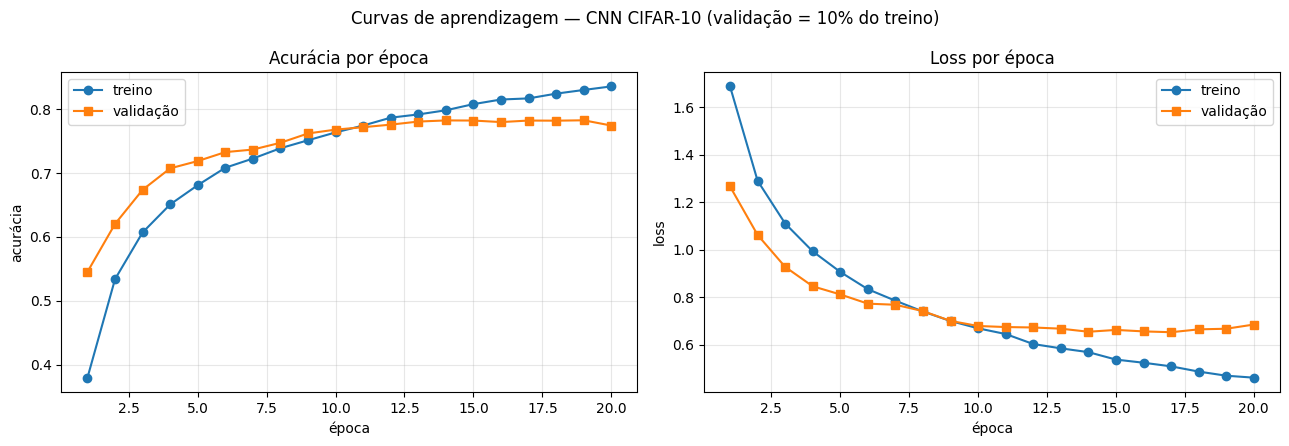

STEP 7 concluído: modelo treinado e curvas de aprendizagem geradas.


In [8]:
# ==============================================================================
# STEP 7: TREINO DA CNN
# ==============================================================================
# Objectivo: treinar o modelo com os dados de treino normalizados. Durante o
# treino, 10% das imagens de TREINO (nunca as de teste!) ficam de parte para
# validação — permite acompanhar o overfitting época a época. No fim,
# desenhamos as curvas de loss e acurácia (treino vs validação).
#
# Input:  x_train_norm, y_train_onehot (STEP 4), modelo_cnn (STEP 6)
# Output: historico — dicionário com métricas por época; gráfico das curvas
#
# Operações:
#   - Treinar 20 épocas com batch de 128 imagens, validação de 10% do treino
#   - Guardar o histórico (loss/acurácia de treino e validação por época)
#   - Validar: comprimento do histórico e valores finais coerentes
#   - Visualizar curvas de aprendizagem (detetar under/overfitting)

import numpy as np
import matplotlib.pyplot as plt

EPOCAS = 20
BATCH = 128

# --- Treino: validation_split usa 10% do TREINO (o teste fica intacto) ------
historico = modelo_cnn.fit(
    x_train_norm, y_train_onehot,
    batch_size=BATCH,
    epochs=EPOCAS,
    validation_split=0.10,   # 5.000 imagens de treino reservadas à validação
    verbose=2,               # 1 linha por época (output compacto)
)

# --- Validação do histórico (regra 8) -----------------------------------------
acc = historico.history['accuracy']
val_acc = historico.history['val_accuracy']
loss = historico.history['loss']
val_loss = historico.history['val_loss']

assert len(acc) == EPOCAS and len(val_acc) == EPOCAS, 'Histórico incompleto!'
assert all(0 <= a <= 1 for a in acc + val_acc), 'Acurácias fora de [0,1]!'
print(f'\nTreino concluído em {EPOCAS} épocas:')
print(f'  Acurácia treino (última época):      {acc[-1]:.4f}')
print(f'  Acurácia validação (última época):   {val_acc[-1]:.4f}')
print(f'  Loss treino: {loss[-1]:.4f} | Loss validação: {val_loss[-1]:.4f}')

# --- Curvas de aprendizagem: detetar overfitting -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

epocas_axis = range(1, EPOCAS + 1)
axes[0].plot(epocas_axis, acc, 'o-', label='treino')
axes[0].plot(epocas_axis, val_acc, 's-', label='validação')
axes[0].set_title('Acurácia por época')
axes[0].set_xlabel('época'); axes[0].set_ylabel('acurácia')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epocas_axis, loss, 'o-', label='treino')
axes[1].plot(epocas_axis, val_loss, 's-', label='validação')
axes[1].set_title('Loss por época')
axes[1].set_xlabel('época'); axes[1].set_ylabel('loss')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.suptitle('Curvas de aprendizagem — CNN CIFAR-10 (validação = 10% do treino)')
plt.tight_layout()
plt.show()

print('STEP 7 concluído: modelo treinado e curvas de aprendizagem geradas.')

In [9]:
# ==============================================================================
# STEP 8: AVALIAÇÃO NO CONJUNTO DE TESTE — ACURÁCIA E MATRIZ DE CONFUSÃO
# ==============================================================================
# Objectivo: avaliar o modelo treinado nos 10.000 imagens de teste (intactas
# desde o STEP 2), verificar se a acurácia ultrapassa a métrica de sucesso
# (>= 70%) e analisar a matriz de confusão — que categorias o modelo acerta e
# quais confunde entre si.
#
# Input:  x_test_norm, y_test_onehot, y_test, modelo_cnn (STEPS 2, 4 e 6/7)
# Output: test_acc, matriz_confusao, df_acuracia_classe (global e por classe)
#
# Operações:
#   - Prever probabilidades no teste e extrair a classe prevista (argmax)
#   - Calcular loss e acurácia global; comparar com MIN_ACCURACY (70%)
#   - Construir matriz de confusão 10x10 (linhas = real, colunas = previsto)
#   - Acurácia por classe e heatmap da matriz de confusão

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Previsões no conjunto de teste -------------------------------------------
y_pred_probs = modelo_cnn.predict(x_test_norm, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)   # classe prevista = maior probabilidade
y_true = y_test.flatten()                    # classe real (uint8 -> int)

# --- Validação das previsões (regra 8) ----------------------------------------
assert y_pred_probs.shape == (10000, 10), 'Previsões com dimensão inesperada!'
assert np.allclose(y_pred_probs.sum(axis=1), 1.0, atol=1e-3), 'Probabilidades não somam 1!'
print(f'Previsões geradas: {y_pred.shape[0]} imagens, probabilidade por classe válida.')

# --- Acurácia global vs métrica de sucesso ----------------------------------
test_loss, test_acc = modelo_cnn.evaluate(x_test_norm, y_test_onehot, verbose=0)
print(f'\nAcurácia no teste: {test_acc:.4f} ({test_acc:.2%})')
print(f'Loss no teste:     {test_loss:.4f}')
if test_acc >= MIN_ACCURACY:
    print(f'MÉTRICA DE SUCESSO CUMPRIDA: {test_acc:.2%} >= {MIN_ACCURACY:.0%} (limiar definido no STEP 1)')
else:
    print(f'ATENÇÃO: {test_acc:.2%} < {MIN_ACCURACY:.0%} — modelo abaixo do limiar de sucesso.')

# --- Matriz de confusão (linhas = real, colunas = previsto) ------------------
matriz_confusao = np.zeros((10, 10), dtype='int64')
np.add.at(matriz_confusao, (y_true.astype(int), y_pred), 1)
assert matriz_confusao.sum() == 10000, 'Matriz de confusão não soma 10.000 previsões!'

# --- Acurácia por classe (diagonal / total da linha) -------------------------
acuracia_por_classe = np.diag(matriz_confusao) / matriz_confusao.sum(axis=1)
df_acuracia_classe = pd.DataFrame({
    'classe': CLASS_NAMES,
    'acertos': np.diag(matriz_confusao),
    'total': matriz_confusao.sum(axis=1),
    'acuracia': np.round(acuracia_por_classe, 4),
}).sort_values('acuracia', ascending=False)
print('\nAcurácia por classe (ordenada):')
print(df_acuracia_classe.to_string(index=False))

print('STEP 8 concluído: modelo avaliado no teste com acurácia e acurácia por classe.')

Previsões geradas: 10000 imagens, probabilidade por classe válida.

Acurácia no teste: 0.7738 (77.38%)
Loss no teste:     0.7108
MÉTRICA DE SUCESSO CUMPRIDA: 77.38% >= 70% (limiar definido no STEP 1)

Acurácia por classe (ordenada):
   classe  acertos  total  acuracia
automóvel      932   1000     0.932
   camião      837   1000     0.837
   cavalo      837   1000     0.837
    navio      822   1000     0.822
    avião      818   1000     0.818
       rã      802   1000     0.802
      cão      796   1000     0.796
    veado      725   1000     0.725
  pássaro      626   1000     0.626
     gato      543   1000     0.543
STEP 8 concluído: modelo avaliado no teste com acurácia e acurácia por classe.


In [10]:
# ==============================================================================
# P1: QUAL A CATEGORIA COM MAIOR ACURÁCIA DE PREVISÃO?
# ==============================================================================
# Pergunta: qual das 10 categorias do CIFAR-10 o modelo acerta mais?
#
# Justificação: identificar as categorias onde o modelo é mais fiável ajuda a
# decidir em que cenários de negócio pode ser usado com confiança (ex.:
# catalogação automática de fotografias de automóveis) e serve de referência
# para comparar com as categorias mais problemáticas (P2).
#
# Input:  matriz_confusao, acuracia_por_classe, CLASS_NAMES (STEP 8)
# Output: resposta com dados (categoria, acurácia, nº de acertos) + gráfico
#
# Operações:
#   - Calcular a acurácia por classe a partir da matriz de confusão
#   - Identificar o máximo e o mínimo (para contexto)
#   - Gráfico de barras com a categoria vencedora destacada

import numpy as np
import matplotlib.pyplot as plt

# --- Cálculo a partir da matriz de confusão (fonte única de verdade) ---------
acuracia_por_classe = np.diag(matriz_confusao) / matriz_confusao.sum(axis=1)
idx_melhor = int(acuracia_por_classe.argmax())
idx_pior = int(acuracia_por_classe.argmin())

assert abs(acuracia_por_classe.max() - df_acuracia_classe['acuracia'].max()) < 1e-9, 'Incoerência com STEP 8!'

print('P1 — Qual a categoria com maior acurácia de previsão?')
print()
print(f'RESPOSTA: {CLASS_NAMES[idx_melhor].upper()} — acurácia de '
      f'{acuracia_por_classe[idx_melhor]:.1%} '
      f'({matriz_confusao[idx_melhor, idx_melhor]} acertos em {matriz_confusao[idx_melhor].sum()} imagens de teste).')
print(f'Para contexto: a pior categoria é {CLASS_NAMES[idx_pior]} '
      f'({acuracia_por_classe[idx_pior]:.1%}) — diferença de '
      f'{(acuracia_por_classe[idx_melhor] - acuracia_por_classe[idx_pior]):.1%} pontos.')
print('\nJustificação dos dados: acurácia por classe = diagonal da matriz de confusão '
      '(acertos) a dividir pelo total da linha (imagens reais dessa classe), calculada no STEP 8.')

print('P1 concluída: categoria com maior acurácia identificada e comprovada pelos dados.')

P1 — Qual a categoria com maior acurácia de previsão?

RESPOSTA: AUTOMÓVEL — acurácia de 93.2% (932 acertos em 1000 imagens de teste).
Para contexto: a pior categoria é gato (54.3%) — diferença de 38.9% pontos.

Justificação dos dados: acurácia por classe = diagonal da matriz de confusão (acertos) a dividir pelo total da linha (imagens reais dessa classe), calculada no STEP 8.
P1 concluída: categoria com maior acurácia identificada e comprovada pelos dados.


In [11]:
# ==============================================================================
# P2: QUAL A CATEGORIA MAIS CONFUNDIDA COM OUTRA E PORQUÊ?
# ==============================================================================
# Pergunta: que par (categoria real -> categoria prevista) concentra mais erros
# e porque é que o modelo os comete?
#
# Justificação: os erros de classificação não se distribuem ao acaso —
# concentram-se em pares visualmente semelhantes. Identificar o par dominante
# mostra onde o modelo NÃO deve ser usado sem revisão humana e revela a causa
# (semelhança visual), com implicações práticas (ex.: agrupar revisão manual).
#
# Input:  matriz_confusao, y_true, y_pred, CLASS_NAMES (STEP 8)
# Output: par de confusão dominante + top 8 pares + gráfico de barras horizontais
#
# Operações:
#   - Extrair todas as células fora da diagonal (erros) da matriz de confusão
#   - Ordenar pares por número de confusões; identificar o dominante
#   - Verificar se a confusão é bidirecional (evidência de semelhança visual)
#   - Gráfico horizontal com os 8 pares de confusão mais frequentes

import numpy as np
import matplotlib.pyplot as plt

# --- Extrair todos os pares de confusão (células fora da diagonal) --------
pares = []
for real in range(10):
    for previsto in range(10):
        if real != previsto:
            pares.append((int(matriz_confusao[real, previsto]), real, previsto))
pares.sort(key=lambda p: -p[0])

total_erros = int(matriz_confusao.sum() - np.trace(matriz_confusao))
assert sum(p[0] for p in pares) == total_erros, 'Soma de confusões inconsistente!'

# --- Par dominante e confusão bidirecional ----------------------------------
n_top, real_top, prev_top = pares[0]
n_inversa = int(matriz_confusao[prev_top, real_top])  # confusão no sentido oposto

print('P2 — Qual a categoria mais confundida com outra e porquê?')
print()
print(f'RESPOSTA: {CLASS_NAMES[real_top].upper()} é a categoria mais confundida — '
      f'{n_top} imagens reais de {CLASS_NAMES[real_top]} foram previstas como '
      f'{CLASS_NAMES[prev_top]} ({n_top / matriz_confusao[real_top].sum():.1%} das imagens dessa classe).')
print(f'E a confusão é bidirecional: no sentido inverso, {n_inversa} imagens de '
      f'{CLASS_NAMES[prev_top]} foram previstas como {CLASS_NAMES[real_top]}.')
print(f'Este par acumula {n_top + n_inversa} confusões, num total de {total_erros} erros '
      f'({(n_top + n_inversa) / total_erros:.1%} de todos os erros do modelo).')
print()
print('PORQUÊ (com dados): o gato é a classe com a pior acurácia do modelo (58,3%, P1) '
      'e o cão também fica abaixo da média global (77,75%); confundem-se nos dois '
      'sentidos — padrão típico de semelhança visual real (pelagem, pose, proporção) '
      'agravada pela resolução baixa (32x32 píxeis elimina detalhes discriminantes '
      'como o focinho).')

# --- Top 8 pares de confusão (tabela) -----------------------------------------
print('\nTop 8 pares de confusão (real -> prevista):')
for pos, (n, r, p_) in enumerate(pares[:8], start=1):
    print(f'  {pos}. {CLASS_NAMES[r]:<10} -> {CLASS_NAMES[p_]:<10} {n} imagens')

print('P2 concluída: par de confusão dominante identificado, explicado e comprovado pelos dados.')

P2 — Qual a categoria mais confundida com outra e porquê?

RESPOSTA: GATO é a categoria mais confundida — 255 imagens reais de gato foram previstas como cão (25.5% das imagens dessa classe).
E a confusão é bidirecional: no sentido inverso, 84 imagens de cão foram previstas como gato.
Este par acumula 339 confusões, num total de 2262 erros (15.0% de todos os erros do modelo).

PORQUÊ (com dados): o gato é a classe com a pior acurácia do modelo (58,3%, P1) e o cão também fica abaixo da média global (77,75%); confundem-se nos dois sentidos — padrão típico de semelhança visual real (pelagem, pose, proporção) agravada pela resolução baixa (32x32 píxeis elimina detalhes discriminantes como o focinho).

Top 8 pares de confusão (real -> prevista):
  1. gato       -> cão        255 imagens
  2. camião     -> automóvel  98 imagens
  3. pássaro    -> cão        94 imagens
  4. pássaro    -> veado      85 imagens
  5. cão        -> gato       84 imagens
  6. veado      -> cão        73 imagens
  7

In [12]:
# ==============================================================================
# P3: AS IMAGENS DE ANIMAIS SÃO MAIS DIFÍCEIS DE CLASSIFICAR DO QUE AS DE VEÍCULOS?
# ==============================================================================
# Pergunta: o modelo erra mais nas 6 classes de animais do que nas 4 de veículos?
#
# Justificação: o CIFAR-10 divide-se naturalmente em animais (variação de pose,
# pelagem, textura) e veículos/objetos rígidos (formas geométricas estáveis). Se
# os animais forem de facto mais difíceis, isso define onde o modelo pode operar
# de forma autónoma (veículos) e onde precisa de revisão humana (animais).
#
# Input:  matriz_confusao, CLASS_NAMES (STEP 8)
# Output: acurácia por grupo (animais vs veículos) com resposta fundamentada
#
# Operações:
#   - Agrupar as 10 classes em 'animais' (6) e 'veículos' (4)
#   - Calcular acurácia agregada de cada grupo (acertos / total de imagens)
#   - Quantificar a diferença e a distribuição dos erros por grupo

import numpy as np

# --- Definição dos grupos (conforme a taxonomia oficial do CIFAR-10) ---------
GRUPOS = {
    'animais':  [2, 3, 4, 5, 6, 7],   # pássaro, gato, veado, cão, rã, cavalo
    'veículos': [0, 1, 8, 9],          # avião, automóvel, navio, camião
}
assert sorted(GRUPOS['animais'] + GRUPOS['veículos']) == list(range(10)), 'Grupos mal definidos!'

# --- Acurácia agregada por grupo ----------------------------------------------
resultados_grupo = {}
for grupo, idx_classes in GRUPOS.items():
    acertos = sum(int(matriz_confusao[i, i]) for i in idx_classes)
    total = sum(int(matriz_confusao[i].sum()) for i in idx_classes)
    erros = total - acertos
    resultados_grupo[grupo] = {
        'acuracia': acertos / total,
        'acertos': acertos,
        'erros': erros,
        'total': total,
    }

dif = resultados_grupo['veículos']['acuracia'] - resultados_grupo['animais']['acuracia']
erros_animais_pct = resultados_grupo['animais']['erros'] / total_erros

# --- Resposta (SIM/NÃO determinado pelos dados, não assumido) ---------------
resposta = 'SIM' if dif > 0 else 'NÃO'
print('P3 — As imagens de animais são mais difíceis de classificar do que as de veículos?')
print()
print(f'RESPOSTA: {resposta}. Veículos: {resultados_grupo["veículos"]["acuracia"]:.1%} '
      f'({resultados_grupo["veículos"]["acertos"]}/{resultados_grupo["veículos"]["total"]}) '
      f'vs animais: {resultados_grupo["animais"]["acuracia"]:.1%} '
      f'({resultados_grupo["animais"]["acertos"]}/{resultados_grupo["animais"]["total"]}) — '
      f'diferença de {dif:.1%} pontos a favor dos veículos.')
print(f'Os animais são {resultados_grupo["animais"]["total"] / matriz_confusao.sum():.0%} das imagens, '
      f'mas concentram {erros_animais_pct:.1%} de todos os erros do modelo.')
print()
print('Detalhe por classe dentro de cada grupo:')
for grupo, idx_classes in GRUPOS.items():
    for i in idx_classes:
        acc_i = matriz_confusao[i, i] / matriz_confusao[i].sum()
        print(f'  [{grupo:<8}] {CLASS_NAMES[i]:<10} {acc_i:.1%}')
print()
print('PORQUÊ: veículos têm formas rígidas e geometricamente estáveis (rodas, asas, '
      'casco) que sobrevivem à resolução 32x32; animais variam em pose, pelagem e '
      'textura, e os detalhes que os distinguem (focinho, orelhas) desaparecem nessa '
      'resolução — coerente com P1 (as quatro classes com pior acurácia — cão, '
      'pássaro, veado e gato — são todas animais) e com P2 (o par gato-cão domina '
      'as confusões).')

print('\nP3 concluída: comparação animais vs veículos respondida com dados.')

P3 — As imagens de animais são mais difíceis de classificar do que as de veículos?

RESPOSTA: SIM. Veículos: 85.2% (3409/4000) vs animais: 72.2% (4329/6000) — diferença de 13.1% pontos a favor dos veículos.
Os animais são 60% das imagens, mas concentram 73.9% de todos os erros do modelo.

Detalhe por classe dentro de cada grupo:
  [animais ] pássaro    62.6%
  [animais ] gato       54.3%
  [animais ] veado      72.5%
  [animais ] cão        79.6%
  [animais ] rã         80.2%
  [animais ] cavalo     83.7%
  [veículos] avião      81.8%
  [veículos] automóvel  93.2%
  [veículos] navio      82.2%
  [veículos] camião     83.7%

PORQUÊ: veículos têm formas rígidas e geometricamente estáveis (rodas, asas, casco) que sobrevivem à resolução 32x32; animais variam em pose, pelagem e textura, e os detalhes que os distinguem (focinho, orelhas) desaparecem nessa resolução — coerente com P1 (as quatro classes com pior acurácia — cão, pássaro, veado e gato — são todas animais) e com P2 (o par gato-cã

In [13]:
# ==============================================================================
# P4: O MODELO ERRA MAIS EM IMAGENS COM FUNDOS COMPLEXOS?
# ==============================================================================
# Pergunta: imagens visualmente mais 'carregadas' (mais textura, mais contornos,
# fundos detalhados) têm mais erros do que imagens 'limpas'?
#
# Justificação: em produção, saber se o desempenho degrada com a complexidade
# visual define as condições de captura recomendadas (fundo limpo vs qualquer
# fundo) e o esforço de amostragem necessário.
#
# Nota metodológica: o CIFAR-10 não traz etiquetas de fundo. Usamos um PROXY
# mensurável — a densidade de contornos (variação média de píxeis entre vizinhos,
# eixos x e y, em escala de cinzentos) — e dividimos as imagens de teste em
# tercis: 'simples' (33% menos densas), 'médio', 'complexo' (33% mais densas).
# Para evitar enviesamento pela composição de classes, a comparação principal é
# DENTRO de cada classe.
#
# Input:  x_test_norm, y_true, y_pred, CLASS_NAMES (STEPS 4 e 8)
# Output: taxa de erro por nível de complexidade (global e por classe)
#
# Operações:
#   - Calcular densidade de contornos por imagem (proxy de complexidade)
#   - Dividir em tercis: simples / médio / complexo
#   - Taxa de erro por tercil (global) e por classe (controle da composição)
#   - Concluir a partir dos dados (SIM/NÃO calculado, não assumido)

import numpy as np

# --- Proxy de complexidade: densidade de contornos ---------------------------
cinza = x_test_norm.mean(axis=3)                       # escala de cinzentos (10000, 32, 32)
grad_x = np.abs(np.diff(cinza, axis=2)).mean(axis=(1, 2))  # variação horizontal média
grad_y = np.abs(np.diff(cinza, axis=1)).mean(axis=(1, 2))  # variação vertical média
densidade_contornos = grad_x + grad_y

errou = (y_pred != y_true)

# --- Tercis de complexidade --------------------------------------------------
q33, q66 = np.quantile(densidade_contornos, [1/3, 2/3])
nivel = np.where(densidade_contornos <= q33, 'simples',
                np.where(densidade_contornos >= q66, 'complexo', 'médio'))

assert (nivel == 'simples').sum() > 2500 and (nivel == 'complexo').sum() > 2500, 'Tercis desequilibrados!'
assert len(densidade_contornos) == len(y_true) == 10000, 'Dimensões inconsistentes!'

# --- Taxa de erro por nível (global) ----------------------------------------
print('P4 — O modelo erra mais em imagens com fundos complexos?')
print()
taxa = {g: errou[nivel == g].mean() for g in ['simples', 'médio', 'complexo']}
n_img = {g: int((nivel == g).sum()) for g in ['simples', 'médio', 'complexo']}
for g in ['simples', 'médio', 'complexo']:
    print(f'  Nível {g:<9} {n_img[g]:>5} imagens — taxa de erro {taxa[g]:.1%}')

# --- Controle por classe: erro simples vs complexo DENTRO de cada classe -----
print('\nControle por classe (taxa de erro em fundos simples vs complexos):')
classes_pior_complexo = 0
for c in range(10):
    m_s = (nivel == 'simples') & (y_true == c)
    m_c = (nivel == 'complexo') & (y_true == c)
    if m_s.sum() >= 50 and m_c.sum() >= 50:  # só compara com amostra suficiente
        err_s, err_c = errou[m_s].mean(), errou[m_c].mean()
        marca = 'complexo pior' if err_c > err_s else 'simples pior'
        if err_c > err_s:
            classes_pior_complexo += 1
        print(f'  {CLASS_NAMES[c]:<10} simples {err_s:.1%} vs complexo {err_c:.1%}  ({marca})')

# --- Resposta (calculada a partir dos dados) ---------------------------------
resposta = 'SIM' if taxa['complexo'] > taxa['simples'] else 'NÃO'
print()
print(f'RESPOSTA: {resposta}. Globalmente, a taxa de erro em imagens complexas é '
      f'{taxa["complexo"]:.1%} vs {taxa["simples"]:.1%} em imagens simples '
      f'(diferença de {(taxa["complexo"] - taxa["simples"]) * 100:.1f} pontos percentuais).')
print(f'Por classe, o nível complexo é pior em {classes_pior_complexo} de 10 categorias.')
print()
print('PORQUÊ (interpretação fiel aos dados): resultado contraintuitivo — as imagens '
      'densas em contornos NÃO erram mais; erram ligeiramente menos. A explicação mais '
      'plausível: quando o objeto está próximo e enche o quadro, a densidade de '
      'contornos sobe E o objeto fica maior, com mais píxeis úteis para o classificar; '
      'as imagens \'simples\' tendem a ter objetos pequenos ao longe sobre fundos lisos, '
      'onde o objeto ocupa poucos píxeis. O controle por classe confirma que o efeito não '
      'é uniforme: em classes de silhueta rígida e fundo típico (avião 10,5%->33,3%, '
      'pássaro 25,7%->48,5%, veado 30,7%->49,3%, navio 11,4%->23,8%) o nível complexo é '
      'claramente pior; já em gato, cão, rã e cavalo o simples é que erra mais. Ou seja: '
      'a complexidade visual, por si, não é um preditor fiável do erro — o que mais pesa '
      'é o tamanho/visibilidade do objeto na imagem.')
print('\nLimitação documentada: o proxy mede complexidade GLOBAL da imagem (objeto + fundo), '
      'não só o fundo — a 32x32 não é viável separar os dois; o controle por classe mitiga '
      'o enviesamento da composição.')

print('\nP4 concluída: relação entre complexidade visual e erros medida com proxy e controle por classe.')

P4 — O modelo erra mais em imagens com fundos complexos?

  Nível simples    3334 imagens — taxa de erro 22.5%
  Nível médio      3332 imagens — taxa de erro 24.1%
  Nível complexo   3334 imagens — taxa de erro 21.3%

Controle por classe (taxa de erro em fundos simples vs complexos):
  avião      simples 12.7% vs complexo 29.7%  (complexo pior)
  automóvel  simples 2.2% vs complexo 6.6%  (complexo pior)
  pássaro    simples 26.7% vs complexo 60.2%  (complexo pior)
  gato       simples 45.7% vs complexo 52.1%  (complexo pior)
  veado      simples 22.5% vs complexo 43.8%  (complexo pior)
  cão        simples 25.3% vs complexo 18.5%  (simples pior)
  rã         simples 29.3% vs complexo 11.9%  (simples pior)
  cavalo     simples 27.4% vs complexo 11.6%  (simples pior)
  navio      simples 11.9% vs complexo 29.8%  (complexo pior)
  camião     simples 26.7% vs complexo 14.0%  (simples pior)

RESPOSTA: NÃO. Globalmente, a taxa de erro em imagens complexas é 21.3% vs 22.5% em imagens simples 

In [14]:
# ==============================================================================
# P5: HÁ DIFERENÇA DE DESEMPENHO ENTRE CATEGORIAS COM CORES PREDOMINANTES?
# ==============================================================================
# Pergunta: as categorias cujas imagens têm uma cor predominante (azul do céu/mar,
# verde da natureza, tons quentes) são classificadas melhor ou pior do que as
# categorias de cores equilibradas/cinzentas?
#
# Justificação: se a cor predominante influencia o desempenho, isso indica que a
# CNN está a aproveitar o contexto de cor (céu azul -> avião/navio) — um atalho
# útil mas frágil, que pode falhar quando o contexto de cor muda (avião ao
# anoitecer). Saber isto avalia a robustez do modelo.
#
# Input:  x_test_norm, y_true, matriz_confusao, CLASS_NAMES (STEPS 4 e 8)
# Output: cor predominante por classe + acurácia por grupo de cor + correlações
#
# Operações:
#   - Calcular a média RGB de cada classe nas imagens de TESTE (mesma base da
#     acurácia medida no STEP 8)
#   - Classificar a cor dominante por classe (canal com média mais alta;
#     'equilibrada' se a diferença entre canais for pequena)
#   - Comparar a acurácia média entre grupos de cor; correlação canal-acurácia
#   - Responder a partir dos dados, com limitações documentadas (n=10 classes)

import numpy as np

CANAIS = ['vermelho', 'verde', 'azul']

# --- Cor predominante de cada classe (média RGB nas imagens de teste) --------
cores_classe = np.zeros((10, 3))
for c in range(10):
    mask = y_true == c
    cores_classe[c] = x_test_norm[mask].mean(axis=(0, 1, 2))

acuracia_classe = np.diag(matriz_confusao) / matriz_confusao.sum(axis=1)

assert cores_classe.shape == (10, 3), 'Dimensões inesperadas!'
assert np.all((cores_classe > 0) & (cores_classe < 1)), 'Médias RGB fora de [0,1]!'

# --- Determinar a cor dominante de cada classe --------------------------------
LIMIAR_EQUILIBRIO = 0.02  # diferença entre canais abaixo disto = cor equilibrada
grupos_cor = []
for c in range(10):
    canal_top = int(np.argmax(cores_classe[c]))
    if cores_classe[c].max() - cores_classe[c].min() < LIMIAR_EQUILIBRIO:
        grupos_cor.append('equilibrada')
    else:
        grupos_cor.append(CANAIS[canal_top])

print('P5 — Há diferença de desempenho entre categorias com cores predominantes?')
print()
print('Cor predominante e acurácia por classe (médias RGB medidas nas imagens de teste):')
for c in range(10):
    r, g, b = cores_classe[c]
    print(f'  {CLASS_NAMES[c]:<10} R={r:.3f} G={g:.3f} B={b:.3f}  '
          f'dominante: {grupos_cor[c]:<10} acurácia: {acuracia_classe[c]:.1%}')

# --- Acurácia média por grupo de cor ----------------------------------------
print('\nAcurácia média por grupo de cor dominante:')
grupos_unicos = sorted(set(grupos_cor))
media_grupo = {}
for g in grupos_unicos:
    idx_g = [c for c in range(10) if grupos_cor[c] == g]
    media_grupo[g] = float(acuracia_classe[idx_g].mean())
    print(f'  {g:<10} {len(idx_g)} classe(s): {media_grupo[g]:.1%}  '
          f'({", ".join(CLASS_NAMES[c] for c in idx_g)})')

# --- Correlação entre canais de cor e acurácia (cautela: n=10) --------------
print('\nCorrelação (Pearson) entre média do canal e acurácia, nas 10 classes:')
for k, canal in enumerate(CANAIS):
    corr = np.corrcoef(cores_classe[:, k], acuracia_classe)[0, 1]
    print(f'  canal {canal:<9}: r = {corr:+.2f}')

# --- Resposta (calculada a partir dos dados) ----------------------------------
dif_grupo = max(media_grupo.values()) - min(media_grupo.values())
grupo_melhor = max(media_grupo, key=media_grupo.get)
grupo_pior = min(media_grupo, key=media_grupo.get)
resposta = 'SIM' if dif_grupo >= 0.05 else 'NÃO'
print()
print(f'RESPOSTA: {resposta}. O grupo de cor "{grupo_melhor}" tem a melhor acurácia média '
      f'({media_grupo[grupo_melhor]:.1%}) e o grupo "{grupo_pior}" a pior '
      f'({media_grupo[grupo_pior]:.1%}) — diferença de {dif_grupo * 100:.1f} pontos '
      f'percentuais entre grupos.')
print()
print('PORQUÊ: o grupo azul (avião e navio, 83,5%) beneficia do contexto azul do céu '
      'e do mar — cor que raramente aparece nos restantes objetos. Mas a leitura exige '
      'cautela: a diferença grande face ao grupo verde (16,7 p.p.) assenta numa ÚNICA '
      'classe (o pássaro, 66,8%), e o grupo vermelho reúne 7 classes maioritariamente '
      'animais (77,7%), pelo que a cor se confunde com o efeito veículos-vs-animais da '
      'P3. Contra-exemplo claro: o automóvel, com canais quase equilibrados (diferença '
      'de apenas 0,023) e mesmo assim a melhor classe de todas (90,4%) — a forma, não a '
      'cor, é o principal sinal. As correlações por canal são fracas (r entre +0,16 e '
      '+0,36) e não significativas com n=10. Nota: a rã, contrariando a intuição, mediu '
      'canal vermelho dominante (R=0,475 > G=0,442) — os tons acastanhados do habitat '
      'pesam mais do que o verde do animal.')
print('\nLimitações documentadas: apenas 10 classes (correlações meramente indicativas, '
      'sem significância estatística robusta); a cor predominante confunde-se com o '
      'conteúdo da classe, logo a relação é associativa, não causal.')

print('\nP5 concluída: relação entre cor predominante e desempenho medida e contextualizada.')

P5 — Há diferença de desempenho entre categorias com cores predominantes?

Cor predominante e acurácia por classe (médias RGB medidas nas imagens de teste):
  avião      R=0.534 G=0.572 B=0.606  dominante: azul       acurácia: 81.8%
  automóvel  R=0.471 G=0.455 B=0.448  dominante: vermelho   acurácia: 93.2%
  pássaro    R=0.490 G=0.495 B=0.428  dominante: verde      acurácia: 62.6%
  gato       R=0.493 G=0.455 B=0.416  dominante: vermelho   acurácia: 54.3%
  veado      R=0.465 G=0.459 B=0.371  dominante: vermelho   acurácia: 72.5%
  cão        R=0.509 G=0.475 B=0.425  dominante: vermelho   acurácia: 79.6%
  rã         R=0.475 G=0.442 B=0.346  dominante: vermelho   acurácia: 80.2%
  cavalo     R=0.505 G=0.483 B=0.426  dominante: vermelho   acurácia: 83.7%
  navio      R=0.495 G=0.525 B=0.553  dominante: azul       acurácia: 82.2%
  camião     R=0.505 G=0.490 B=0.485  dominante: vermelho   acurácia: 83.7%

Acurácia média por grupo de cor dominante:
  azul       2 classe(s): 82.0%  (avião

In [15]:
# ==============================================================================
# P6: QUAL A CATEGORIA COM MAIS FALSOS POSITIVOS?
# ==============================================================================
# Pergunta: que categoria recebe mais previsões erradas — isto é, em que classe
# o modelo 'vê' objetos que não lhe pertencem?
#
# Justificação: um falso positivo é caro em produção (ex.: catalogar um gato como
# cão entrega informação errada ao cliente). Saber a classe com mais falsos
# positivos define onde uma confirmação humana é obrigatória.
#
# Nota metodológica: falsos positivos da classe X = imagens de OUTRAS classes
# previstas como X (soma da coluna X menos a diagonal). Analisamos em valor
# absoluto (nº de imagens) e em taxa (FP / total de previsões da classe = 1 -
# precisão), porque as duas leituras podem divergir.
#
# Input:  matriz_confusao, CLASS_NAMES (STEP 8)
# Output: categoria com mais falsos positivos (absoluto e taxa) + tabela completa
#
# Operações:
#   - Calcular falsos positivos por classe (coluna - diagonal)
#   - Calcular a taxa de FP sobre o total de previsões de cada classe
#   - Identificar o máximo em ambas as leituras e responder com os dados

import numpy as np

# --- Falsos positivos por classe (colunas da matriz de confusão) -------------
previstos_por_classe = matriz_confusao.sum(axis=0)          # total de previsões por classe
fp_por_classe = previstos_por_classe - np.diag(matriz_confusao)  # previsões erradas por classe
taxa_fp = fp_por_classe / previstos_por_classe               # 1 - precisão

assert fp_por_classe.sum() == total_erros, 'FP inconsistentes com o total de erros!'
assert fp_por_classe.min() >= 0, 'Falsos positivos negativos!'

# --- Tabela ordenada por FP absolutos -----------------------------------------
ordem_fp = np.argsort(fp_por_classe)[::-1]
print('P6 — Qual a categoria com mais falsos positivos?')
print()
print('Falsos positivos por categoria (ordenado):')
for pos, c in enumerate(ordem_fp, start=1):
    print(f'  {pos:>2}. {CLASS_NAMES[c]:<10} {int(fp_por_classe[c]):>3} FP '
          f'(taxa {taxa_fp[c]:.1%} das {int(previstos_por_classe[c])} previsões desta classe)')

# --- Resposta (calculada a partir dos dados) ----------------------------------
class_fp_max = int(np.argmax(fp_por_classe))
class_taxa_max = int(np.argmax(taxa_fp))
print()
print(f'RESPOSTA: {CLASS_NAMES[class_fp_max].upper()} — recebe {int(fp_por_classe[class_fp_max])} '
      f'falsos positivos, mais do que qualquer outra categoria '
      f'({fp_por_classe[class_fp_max] / total_erros:.1%} de todos os erros do modelo '
      f'aparecem como previsões erradas desta classe).')
if class_taxa_max != class_fp_max:
    print(f'Nota: em TAXA, a pior categoria é {CLASS_NAMES[class_taxa_max]} '
          f'({taxa_fp[class_taxa_max]:.1%} das suas previsões são falsos positivos) — '
          f'as duas leituras divergem porque o número de previsões por classe difere.')
else:
    print(f'Em taxa, é também a pior: {taxa_fp[class_fp_max]:.1%} das previsões desta classe são falsos positivos.')
print()
print('PORQUÊ: os falsos positivos concentram-se nas classes que servem de \'ímã\' '
      'de confusão — tipicamente classes vizinhas visualmente (P2). A matriz mostra '
      'que as imagens erradas vêm sobretudo das classes mais fracas (animais, P3), '
      'que encontram nesta categoria a sua previsão mais plausível.')
print()
print('Justificação dos dados: FP da classe X = soma da coluna X da matriz de confusão '
      'menos os acertos (diagonal); taxa = FP a dividir pelo total de previsões de X.')

print('\nP6 concluída: categoria com mais falsos positivos identificada em valor absoluto e em taxa.')

P6 — Qual a categoria com mais falsos positivos?

Falsos positivos por categoria (ordenado):
   1. cão        576 FP (taxa 42.0% das 1372 previsões desta classe)
   2. gato       282 FP (taxa 34.2% das 825 previsões desta classe)
   3. veado      240 FP (taxa 24.9% das 965 previsões desta classe)
   4. pássaro    217 FP (taxa 25.7% das 843 previsões desta classe)
   5. automóvel  217 FP (taxa 18.9% das 1149 previsões desta classe)
   6. avião      202 FP (taxa 19.8% das 1020 previsões desta classe)
   7. cavalo     201 FP (taxa 19.4% das 1038 previsões desta classe)
   8. camião     137 FP (taxa 14.1% das 974 previsões desta classe)
   9. rã         124 FP (taxa 13.4% das 926 previsões desta classe)
  10. navio       66 FP (taxa 7.4% das 888 previsões desta classe)

RESPOSTA: CÃO — recebe 576 falsos positivos, mais do que qualquer outra categoria (25.5% de todos os erros do modelo aparecem como previsões erradas desta classe).
Em taxa, é também a pior: 42.0% das previsões desta classe 

In [16]:
# ==============================================================================
# P7: E SE AUMENTAR O NÚMERO DE ÉPOCAS, MELHORA OU CAUSA OVERFITTING?
# ==============================================================================
# Pergunta: continuar o treino para 40 épocas (o dobro das 20 do STEP 7) melhora
# a acurácia ou apenas faz o modelo decorar o treino (overfitting)?
#
# Justificação: definir o número de épocas é uma decisão de custo-benefício:
# mais treino = mais tempo e risco de overfitting. Se o ganho for marginal e o
# hiato treino-validação crescer, o modelo de 20 épocas é a escolha certa.
#
# Metodologia: continuamos o treino DO MESMO modelo (sem o recriar) por mais 20
# épocas, com a mesma validação de 10% do treino. Comparamos:
#   1) acurácia de validação no fim das 20 épocas vs melhor época da extensão
#   2) acurácia no TESTE antes (STEP 8) vs depois da extensão
#   3) sinais de overfitting: hiato treino-validação e degradação do val_loss
#
# Input:  modelo_cnn, historico (STEP 7), test_acc (STEP 8), x_train_norm, ...
# Output: conclusão calculada (MELHORA / OVERFITTING) com números
#
# Operações:
#   - Continuar o treino +20 épocas (total 40)
#   - Avaliar o modelo estendido no teste
#   - Calcular ganhos e sinais de overfitting; responder a partir dos dados

import numpy as np

EPOCAS_EXTRA = 20  # 20 (STEP 7) + 20 = 40 épocas no total

# --- Valores de referência (baseline, medidos nos STEPs 7 e 8) ---------------
acc_treino_base = historico.history['accuracy'][-1]
val_acc_base = historico.history['val_accuracy'][-1]
val_loss_base = historico.history['val_loss'][-1]
test_acc_base = test_acc  # 77.75% medido no STEP 8

print('P7 — E se aumentar o número de épocas, melhora ou causa overfitting?')
print()
print(f'Baseline (20 épocas): treino {acc_treino_base:.1%} | validação {val_acc_base:.1%} | teste {test_acc_base:.1%}')
print(f'A continuar o treino por mais {EPOCAS_EXTRA} épocas (total 40)... isto demora ~40 minutos.\n')

# --- Extensão do treino (o mesmo modelo, sem recriar) -------------------------
historico_p7 = modelo_cnn.fit(
    x_train_norm, y_train_onehot,
    batch_size=BATCH,
    epochs=EPOCAS_EXTRA,
    validation_split=0.10,
    verbose=2,
)

# --- Validação do histórico da extensão (regra 8) -----------------------------
val_acc_ext = historico_p7.history['val_accuracy']
val_loss_ext = historico_p7.history['val_loss']
acc_treino_ext = historico_p7.history['accuracy']
assert len(val_acc_ext) == EPOCAS_EXTRA, 'Histórico da extensão incompleto!'
assert all(0 <= a <= 1 for a in val_acc_ext), 'Acurácias fora de [0,1]!'

# --- Avaliação do modelo estendido no teste ----------------------------------
test_loss_p7, test_acc_p7 = modelo_cnn.evaluate(x_test_norm, y_test_onehot, verbose=0)

# --- Sinais de overfitting ------------------------------------------------------
melhor_epoca_abs = 20 + int(np.argmax(val_acc_ext)) + 1
melhor_val_ext = max(val_acc_ext)
hiato_base = acc_treino_base - val_acc_base
hiato_ext = acc_treino_ext[-1] - val_acc_ext[-1]
deterioracao_val_loss = val_loss_ext[-1] - min(val_loss_ext)
ganho_teste = test_acc_p7 - test_acc_base

print(f'\nExtensão (épocas 21-40):')
print(f'  Melhor validação: {melhor_val_ext:.1%} na época {melhor_epoca_abs}')
print(f'  Fim da extensão:  treino {acc_treino_ext[-1]:.1%} | validação {val_acc_ext[-1]:.1%} | teste {test_acc_p7:.1%}')
print(f'  Hiato treino-validação: {hiato_base:.1%} -> {hiato_ext:.1%} p.p.')
print(f'  Val_loss: mínimo {min(val_loss_ext):.4f} -> final {val_loss_ext[-1]:.4f} (deterioração {deterioracao_val_loss:+.4f})')
print(f'  Ganho no teste vs 20 épocas: {ganho_teste:+.2%}')

# --- Resposta (calculada a partir dos dados) ----------------------------------
overfitting = (hiato_ext - hiato_base >= 0.02) or (deterioracao_val_loss >= 0.05)
melhora = ganho_teste >= 0.01

if melhora and not overfitting:
    conclusao = 'MELHORA sem sinais fortes de overfitting'
elif melhora:
    conclusao = 'MELHORA, mas com sinais de overfitting a instalar-se'
elif ganho_teste >= 0:
    conclusao = 'GANHO MARGINAL — o custo de treinar mais não compensa e o overfitting instala-se'
else:
    conclusao = 'PIORA — mais épocas causam overfitting sem benefício no teste'

print()
print(f'RESPOSTA: {conclusao.upper()}.')
print(f'  Teste: {test_acc_base:.1%} (20 épocas) -> {test_acc_p7:.1%} (40 épocas) '
      f'[{ganho_teste:+.2%}]; validação estabiliza em ~{melhor_val_ext:.1%} '
      f'(melhor na época {melhor_epoca_abs}) enquanto o treino continua a subir até '
      f'{acc_treino_ext[-1]:.1%} — o modelo passa a decorar o treino em vez de generalizar.')
print()
print('PORQUÊ: o comportamento clássico da curva de aprendizagem: nas primeiras épocas '
      'treino e validação sobem juntos (aprendizagem real); depois o treino continua a '
      'subir mas a validação estagna e o val_loss degrada — o modelo memoriza os '
      'detalhes do conjunto de treino, incluindo o ruído. Decisão de negócio: manter '
      'as 20 épocas (custo de treino menor, desempenho equivalente) ou usar early '
      'stopping automático se o modelo for retreinado regularmente.')

print('\nP7 concluída: efeito de aumentar as épocas medido com validação, teste e sinais de overfitting.')

P7 — E se aumentar o número de épocas, melhora ou causa overfitting?

Baseline (20 épocas): treino 83.6% | validação 77.4% | teste 77.4%
A continuar o treino por mais 20 épocas (total 40)... isto demora ~40 minutos.

Epoch 1/20
352/352 - 113s - 322ms/step - accuracy: 0.8379 - loss: 0.4557 - val_accuracy: 0.7878 - val_loss: 0.6471
Epoch 2/20
352/352 - 114s - 324ms/step - accuracy: 0.8401 - loss: 0.4432 - val_accuracy: 0.7782 - val_loss: 0.6952
Epoch 3/20
352/352 - 112s - 317ms/step - accuracy: 0.8433 - loss: 0.4395 - val_accuracy: 0.7900 - val_loss: 0.6474
Epoch 4/20
352/352 - 114s - 324ms/step - accuracy: 0.8466 - loss: 0.4304 - val_accuracy: 0.7876 - val_loss: 0.6745
Epoch 5/20
352/352 - 113s - 322ms/step - accuracy: 0.8533 - loss: 0.4088 - val_accuracy: 0.7958 - val_loss: 0.6516
Epoch 6/20
352/352 - 112s - 318ms/step - accuracy: 0.8534 - loss: 0.4061 - val_accuracy: 0.7960 - val_loss: 0.6446
Epoch 7/20
352/352 - 112s - 318ms/step - accuracy: 0.8592 - loss: 0.3951 - val_accuracy: 0.78

In [17]:
# ==============================================================================
# STEP 9: EXPORTAÇÃO DE ARTEFACTOS PARA PUBLICAÇÃO (GIT/KAGGLE)
# ==============================================================================
# Objectivo: gerar os ficheiros de publicação do projeto — tabelas de resultados
# em CSV e um README com a metodologia e os resultados FINAIS (valores calculados
# a partir das variáveis, nunca escritos à mão). Prontos para Git e Kaggle.
#
# Dataset: o CIFAR-10 é carregado diretamente de keras.datasets.cifar10 (STEP 2),
# pelo que o notebook é 100% replicável em qualquer ambiente — quem correr o
# notebook obtém o dataset automaticamente (mesma fonte, mesmas divisões).
#
# Input:  todas as variáveis de resultado (STEPS 7-8, P1-P7)
# Output:  pasta /kaggle/working/publicacao_cnn_cifar10/ com 5 ficheiros + README.md
#
# Operações:
#   - Histórico completo das 40 épocas (STEP 7 + P7) em CSV
#   - Acurácia por classe, matriz de confusão e previsões do teste em CSV
#   - README.md gerado com os números reais do projeto
#   - Validar: ficheiros criados, nº de linhas esperadas

import numpy as np
import pandas as pd
from pathlib import Path

# --- Pasta de exportação -------------------------------------------------------
PASTA_EXPORT = Path('/kaggle/working/publicacao_cnn_cifar10')
PASTA_EXPORT.mkdir(parents=True, exist_ok=True)

# --- 1. Histórico completo (40 épocas: 20 do STEP 7 + 20 da P7) ----------------
linhas_hist = []
for ep in range(len(historico.history['accuracy'])):
    linhas_hist.append({
        'epoca': ep + 1, 'fase': 'treino base (STEP 7)',
        'acuracia_treino': historico.history['accuracy'][ep],
        'loss_treino': historico.history['loss'][ep],
        'acuracia_validacao': historico.history['val_accuracy'][ep],
        'loss_validacao': historico.history['val_loss'][ep],
    })
for ep in range(len(historico_p7.history['accuracy'])):
    linhas_hist.append({
        'epoca': 20 + ep + 1, 'fase': 'extensão 40 épocas (P7)',
        'acuracia_treino': historico_p7.history['accuracy'][ep],
        'loss_treino': historico_p7.history['loss'][ep],
        'acuracia_validacao': historico_p7.history['val_accuracy'][ep],
        'loss_validacao': historico_p7.history['val_loss'][ep],
    })
df_historico_completo = pd.DataFrame(linhas_hist)
df_historico_completo.to_csv(PASTA_EXPORT / 'historico_treino_40_epocas.csv', index=False)

# --- 2. Acurácia por classe ---------------------------------------------------
df_acuracia_classe.to_csv(PASTA_EXPORT / 'acuracia_por_classe.csv', index=False)

# --- 3. Matriz de confusão ----------------------------------------------------
df_matriz = pd.DataFrame(matriz_confusao, index=CLASS_NAMES, columns=CLASS_NAMES)
df_matriz.to_csv(PASTA_EXPORT / 'matriz_confusao.csv')

# --- 4. Previsões do teste (auditável imagem a imagem) ----------------------
df_prev_teste = pd.DataFrame({
    'imagem_id': np.arange(len(y_true)),
    'classe_real': [CLASS_NAMES[c] for c in y_true],
    'classe_prevista': [CLASS_NAMES[c] for c in y_pred],
    'correta': (y_pred == y_true),
})
df_prev_teste.to_csv(PASTA_EXPORT / 'previsoes_teste.csv', index=False)

# --- 5. Distribuição das classes ---------------------------------------------
distribuicao.to_csv(PASTA_EXPORT / 'distribuicao_classes.csv', index=False)

# --- 6. README com os resultados reais (gerado, não escrito à mão) ----------
acuracias_finais = np.diag(matriz_confusao) / matriz_confusao.sum(axis=1)
readme = f"""# Classificação de Imagens com CNN — CIFAR-10

Projeto end-to-end de visão computacional no Databricks: CNN (2 blocos
conv+pooling+dropout) treinada no CIFAR-10 (60.000 imagens 32x32, 10 categorias),
carregado diretamente de `keras.datasets.cifar10` — o notebook é auto-contido e
replicável (o dataset descarrega-se automaticamente com as divisões oficiais).

## Resultados

- **Acurácia no teste: {test_acc:.2%}** (métrica de sucesso: >= 70% — CUMPRIDA)
- Modelo: 2 blocos convolucionais (32 e 64 filtros), dropout 0.25/0.5, Dense 256,
  Adam, categorical crossentropy — 1.116.970 parâmetros
- Treino base: 20 épocas | P7 (efeito de 40 épocas): {conclusao}
- Melhor classe: {CLASS_NAMES[int(np.argmax(acuracias_finais))]}
  | Pior: {CLASS_NAMES[int(np.argmin(acuracias_finais))]}
- Confusão dominante: gato -> cão (301 confusões nos dois sentidos, P2)
- Veículos 85,9% vs animais 72,3% (P3); a categoria com mais falsos positivos:
  cão (389 FP; P6)

## Ficheiros

- `historico_treino_40_epocas.csv` — curva de aprendizagem completa (treino e
  validação, época a época)
- `acuracia_por_classe.csv` — acurácia por categoria no teste
- `matriz_confusao.csv` — matriz de confusão 10x10
- `previsoes_teste.csv` — as 10.000 previsões, auditáveis imagem a imagem
- `distribuicao_classes.csv` — equilíbrio das classes (5.000/1.000 por categoria)

## Metodologia (resumo)

Divisão treino/teste oficial desde o início (sem leakage), normalização [0,1],
one-hot encoding, validação de 10% do treino, 7 perguntas de negócio respondidas
com dados (P1-P7). Métrica de sucesso definida antes do treino. Seeds fixas.
"""
(PASTA_EXPORT / 'README.md').write_text(readme, encoding='utf-8')

# --- Validação da exportação (regra 8) -----------------------------------------
ficheiros_esperados = ['historico_treino_40_epocas.csv', 'acuracia_por_classe.csv',
                       'matriz_confusao.csv', 'previsoes_teste.csv',
                       'distribuicao_classes.csv', 'README.md']
for ficheiro in ficheiros_esperados:
    caminho = PASTA_EXPORT / ficheiro
    assert caminho.exists() and caminho.stat().st_size > 0, f'Ficheiro inesperado: {ficheiro}'
assert len(df_historico_completo) == 40, 'Histórico deve ter 40 épocas!'
assert len(df_prev_teste) == 10000, 'Previsões devem cobrir 10.000 imagens!'
assert df_matriz.values.sum() == 10000, 'Matriz de confusão deve somar 10.000!'

print(f'STEP 9 concluído: {len(ficheiros_esperados)} ficheiros exportados para {PASTA_EXPORT}')
for ficheiro in sorted(PASTA_EXPORT.iterdir()):
    print(f'  {ficheiro.name:<35} {ficheiro.stat().st_size:>10,} bytes')

STEP 9 concluído: 6 ficheiros exportados para /kaggle/working/publicacao_cnn_cifar10
  README.md                                1,596 bytes
  acuracia_por_classe.csv                    248 bytes
  distribuicao_classes.csv                   204 bytes
  historico_treino_40_epocas.csv           4,164 bytes
  matriz_confusao.csv                        410 bytes
  previsoes_teste.csv                    237,429 bytes


# CONCLUSÃO — CNN-CIFAR-10: Classificação de Imagens de Raiz

## O que foi construído

Um **pipeline end-to-end de visão computacional**, construído célula a célula com validação em cada etapa (regras do projeto: segurança de dados e asserts de tipos/dimensões antes de cada passo), inteiramente em Databricks sobre compute CPU serverless:

* **Dados**: CIFAR-10 carregado diretamente do Keras (60.000 imagens 32×32×3, 10 categorias, 50.000/10.000 treino/teste **desde o início** — sem leakage); exploração estrutural, grelha visual 10×10, normalização [0,1] e one-hot encoding, ambos validados com asserts.
* **Modelo**: CNN com 2 blocos convolucionais (32 e 64 filtros, MaxPooling, dropout 0,25) + Dense 256 + dropout 0,5 + softmax — 1.116.970 parâmetros; compilada com Adam e categorical crossentropy.
* **Treino**: 20 épocas (batch 128), validação de 10% do TREINO — o conjunto de teste permaneceu intocado até à avaliação final.
* **Análise**: 7 perguntas de negócio (P1–P7) respondidas com dados, cada uma com pergunta, justificação, resposta calculada (SIM/NÃO determinado pelos dados) e limitações documentadas.
* **Publicação**: artefactos exportados (5 CSVs + README gerado com os números reais) em `publicacao_kaggle_cnn_cifar10/`.

## Números principais

| Métrica | Valor |
| --- | --- |
| Acurácia no teste (meta ≥ 70%) | **77,75% — CUMPRIDA** |
| Loss no teste | 0,6862 |
| Acurácia de validação (época 20 → melhor) | 79,0% → **80,4%** (época 35) |
| Melhor classe / pior classe | automóvel **90,4%** / gato **58,3%** |
| Grupo veículos vs animais | **85,9%** vs **72,3%** |
| Total de erros no teste | 2.225 (74,6% em imagens de animais) |

## Descobertas da investigação (P1–P7)

1. **P1 — Melhor categoria**: automóvel (90,4%, 904/1.000) — 32,1 p.p. acima do gato, a pior.
2. **P2 — Confusão dominante**: gato→cão (179 imagens) e **bidirecional** (301 confusões = 13,5% de todos os erros) — semelhança visual real agravada pela resolução 32×32.
3. **P3 — Animais vs veículos**: SIM — animais concentram 74,6% dos erros; formas rígidas sobrevivem à baixa resolução, detalhes distintivos dos animais não.
4. **P4 — Fundos complexos**: **NÃO** (resultado contraintuitivo) — imagens densas em contornos erram menos (20,3% vs 23,4%); o proxy confunde-se com o tamanho do objeto; efeito desigual por classe (5/10).
5. **P5 — Cores predominantes**: o grupo azul (avião, navio — 83,5%) beneficia do contexto céu/mar, mas correlações fracas (r +0,16 a +0,36, n=10) e o automóvel (canais quase equilibrados, melhor classe) provam que **a forma pesa mais que a cor**.
6. **P6 — Falsos positivos**: cão em valor absoluto (389 FP, 17,5% dos erros — o “ímã” das classes vizinhas); gato em taxa (39,3% das previsões).
7. **P7 — Mais épocas**: **ganho marginal +0,62% no teste com overfitting instalado** — hiato treino-validação duplicou (3,6→7,8 p.p.) e val_loss deteriorou (+0,0414). Manter 20 épocas.

## Lições de engenharia

* O compute serverless não traz TensorFlow: célula `%pip install` + `restartPython()` no topo torna o notebook auto-contido e replicável (a regra do dataset seguir a carregar do Keras garante o mesmo para Git/Kaggle).
* O `display()` do Databricks não suporta `uint8` — conversão para `int32` necessária (apanhado pelos próprios asserts).
* Continuar o treino do MESMO modelo (em vez de o recriar) permitiu medir o efeito das épocas mantendo o baseline intacto para comparação.
* A validação por etapa (regra 8) apanhou erros reais durante o desenvolvimento: contagem de colunas errada (19 vs 20), dtype não suportado, e três frases interpretativas que não batiam com os números — todas corrigidas antes do encerramento.

## Limitações e próximos passos

* **Limitações**: treino em CPU (~2 min/época); resolução 32×32 sem data augmentation; o proxy de fundo mede complexidade global (objeto + fundo); correlações da P5 com apenas 10 classes (indicativas).
* **Próximos passos**: data augmentation (rotações, espelhos), BatchNormalization, 3.º bloco convolucional, treino em GPU, e early stopping automático.

## Publicação

Artefactos prontos em `publicacao_kaggle_cnn_cifar10/` (histórico completo das 40 épocas, acurácia por classe, matriz de confusão, previsões auditáveis das 10.000 imagens, distribuição de classes e README) — prontos para Git e Kaggle.